Assignment 7 by Chris 

On the Wine dataset, I will perform exploratory data analysis (EDA), feature scaling, polynomial feature creation, model training, prediction, and evaluation for a multiclass classification task.

Library Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

Load the Wine Dataset & Split into Train-Test Sets

In [2]:
# Load the Wine classification dataset as a pandas DataFrame.
wine_data = load_wine(as_frame=True)
df = wine_data.frame

# Split into train-test sets (80/20 split), preserving class proportions.
X_train, X_test, y_train, y_test = train_test_split(
    wine_data.data,
    wine_data.target,
    test_size=0.2,
    random_state=42,
    stratify=wine_data.target
)

Exploratory Data Analysis (EDA)

In [3]:
print(X_train.info())      # Overview of the dataset
print(X_train.describe())  # Summary statistics
print(X_train.head())      # Display first few rows

<class 'pandas.DataFrame'>
Index: 142 entries, 36 to 131
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       142 non-null    float64
 1   malic_acid                    142 non-null    float64
 2   ash                           142 non-null    float64
 3   alcalinity_of_ash             142 non-null    float64
 4   magnesium                     142 non-null    float64
 5   total_phenols                 142 non-null    float64
 6   flavanoids                    142 non-null    float64
 7   nonflavanoid_phenols          142 non-null    float64
 8   proanthocyanins               142 non-null    float64
 9   color_intensity               142 non-null    float64
 10  hue                           142 non-null    float64
 11  od280/od315_of_diluted_wines  142 non-null    float64
 12  proline                       142 non-null    float64
dtypes: float64(13)
memor

Correlation Heatmap

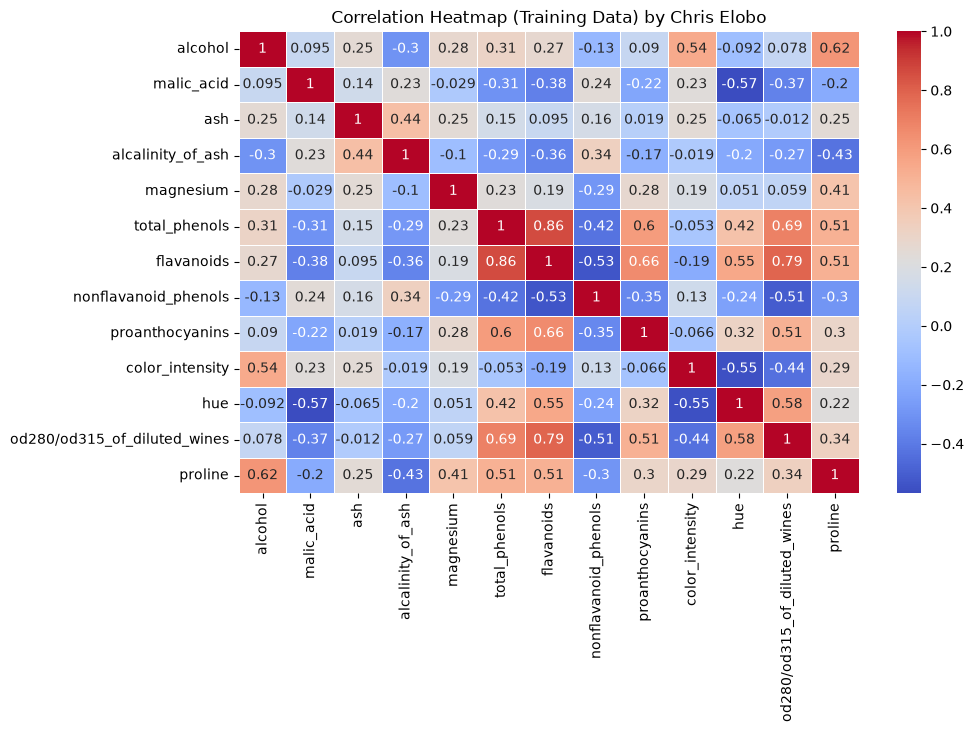

In [4]:
plt.figure(figsize=(10, 6))
sns.heatmap(X_train.corr(), annot=True, cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Heatmap (Training Data) by Chris Elobo")
plt.show()

Pairplot of Selected Features

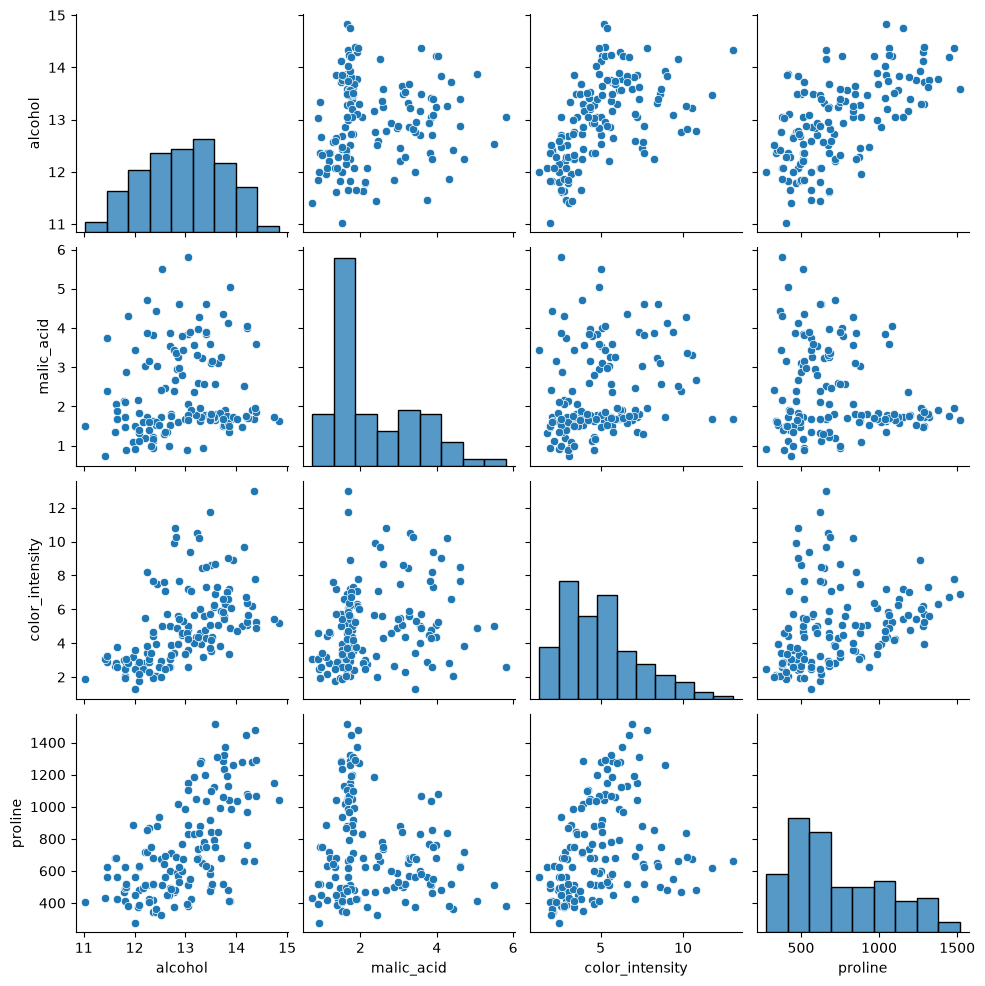

In [5]:
sns.pairplot(X_train[['alcohol', 'malic_acid', 'color_intensity', 'proline']])
plt.show()

Wine Class Distribution (Training Set)

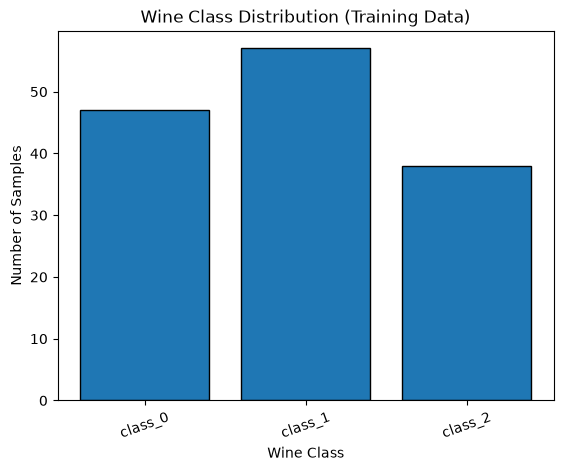

In [6]:
class_counts = y_train.value_counts().sort_index()
plt.bar(wine_data.target_names[class_counts.index.to_numpy()], class_counts.values, edgecolor='black')
plt.title("Wine Class Distribution (Training Data)")
plt.xlabel("Wine Class")
plt.ylabel("Number of Samples")
plt.xticks(rotation=20)
plt.show()

Feature Scaling (StandardScaler)

In [7]:
scaler = StandardScaler()

# Scale the training set
X_train_scaled = scaler.fit_transform(X_train)

# Scale the test set
X_test_scaled = scaler.transform(X_test)

# Convert scaled data back into DataFrames for easier handling
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=X_test.columns)

# Inspect the scaled training set
print(X_train_scaled_df.head())

    alcohol  malic_acid       ash  alcalinity_of_ash  magnesium  \
0  0.385801   -0.637871  1.776668          -1.224532   0.696430   
1  0.948519   -0.765445  1.253174           0.853284   0.091785   
2  0.523354   -0.519409  0.954034          -1.046433  -0.445678   
3  0.973529   -0.555859  0.168793          -1.076116  -0.714409   
4  0.435820    0.820120  0.056615           0.556453  -0.512860   

   total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  \
0       0.526865    0.732292             -0.169549        -0.415783   
1       1.172795    1.333181             -0.590457         1.349742   
2       0.930572    1.006382             -0.169549        -0.260002   
3       0.526865    0.816627             -0.590457         0.363125   
4      -0.555068   -1.291756              0.756449        -0.606183   

   color_intensity       hue  od280/od315_of_diluted_wines   proline  
0        -0.167467  0.624378                      0.252908  0.467725  
1         0.305303  1.067155

Create Polynomial Features

In [8]:
poly = PolynomialFeatures(degree=2, include_bias=False)

# Create polynomial features for training and test sets
X_train_poly = poly.fit_transform(X_train_scaled_df)
X_test_poly = poly.transform(X_test_scaled_df)

Model Training (Multiclass Logistic Regression)

In [9]:
lr_model = LogisticRegression(max_iter=5000)
lr_model.fit(X_train_poly, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",5000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

Model Prediction and Evaluation

In [10]:
y_pred = lr_model.predict(X_test_poly)
print(f"Test accuracy: {accuracy_score(y_test, y_pred):.3f}")
print(classification_report(y_test, y_pred, target_names=wine_data.target_names))

Test accuracy: 0.972
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       0.93      1.00      0.97        14
     class_2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36



Feature Scaling (MinMaxScaler)

In [11]:
min_max_scaler = MinMaxScaler()

# Min-Max scale the training and test sets
X_train_minmax = min_max_scaler.fit_transform(X_train)
X_test_minmax = min_max_scaler.transform(X_test)

# Convert to DataFrames for easier handling
X_train_minmax_df = pd.DataFrame(X_train_minmax, columns=X_train.columns)
X_test_minmax_df = pd.DataFrame(X_test_minmax, columns=X_test.columns)

# Inspect the scaled training set
print(X_train_minmax_df.head())

    alcohol  malic_acid       ash  alcalinity_of_ash  magnesium  \
0  0.592105    0.177866  0.795699           0.252577   0.434783   
1  0.710526    0.150198  0.720430           0.613402   0.336957   
2  0.621053    0.203557  0.677419           0.283505   0.250000   
3  0.715789    0.195652  0.564516           0.278351   0.206522   
4  0.602632    0.494071  0.548387           0.561856   0.239130   

   total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  \
0       0.558621    0.688235                  0.42         0.297468   
1       0.696552    0.855882                  0.32         0.620253   
2       0.644828    0.764706                  0.42         0.325949   
3       0.558621    0.711765                  0.32         0.439873   
4       0.327586    0.123529                  0.64         0.262658   

   color_intensity       hue  od280/od315_of_diluted_wines   proline  
0         0.283276  0.495935                      0.569811  0.486661  
1         0.377133  0.577236

Further Analysis: L1-Regularized Classification

In [12]:
from sklearn.linear_model import LogisticRegression

# Train a Logistic Regression model with L1 regularization.
lasso_model = LogisticRegression(solver='saga', l1_ratio=1.0, C=1.0, max_iter=5000, random_state=42)
lasso_model.fit(X_train_poly, y_train)

# Predict on the test set
y_pred_lasso = lasso_model.predict(X_test_poly)

# Evaluate the L1-regularized classifier.
print(f"L1 Logistic Regression accuracy: {accuracy_score(y_test, y_pred_lasso):.3f}")

L1 Logistic Regression accuracy: 0.972


Cross-Validation (Classification Accuracy):

In [13]:
from sklearn.model_selection import cross_val_score

# Evaluate multiclass classification with stratified cross-validation.
cross_val_accuracy = cross_val_score(lr_model, X_train_poly, y_train, cv=5, scoring='accuracy')
print(f"Cross-Validated Accuracy: {cross_val_accuracy.mean():.3f} +/- {cross_val_accuracy.std():.3f}")

Cross-Validated Accuracy: 0.986 +/- 0.017
